<a href="https://colab.research.google.com/github/Paul412399/PROIECT-PI/blob/main/Antrenament_Pose_Estimation_Vaci.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
### Celula 1 — Instalează Ultralytics

!pip -q install -U ultralytics

In [2]:
### Celula 2 — Încarcă arhiva

from google.colab import files

uploaded = files.upload()

Saving vaci.zip to vaci.zip


In [3]:
### Celula 3 — Dezarhivează datele și pregătește YAML-ul

import zipfile
from pathlib import Path
import yaml

ZIP_PATH = Path("/content/vaci.zip")
EXTRACT_DIR = Path("/content/cow_data")

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Nu găsesc arhiva aici: {ZIP_PATH}. "
        "Verifică dacă ai încărcat vaci.zip în Colab."
    )

with zipfile.ZipFile(ZIP_PATH) as archive:
    archive.extractall(EXTRACT_DIR)

dataset_root = next(
    (
        p.parent for p in EXTRACT_DIR.rglob("data.yaml")
        if (p.parent / "train" / "images").is_dir()
        and (p.parent / "valid" / "images").is_dir()
        and (p.parent / "test" / "images").is_dir()
    ),
    None
)

if dataset_root is None:
    raise FileNotFoundError(
        "Nu am găsit folderele train/images, valid/images și test/images."
    )

data = yaml.safe_load((dataset_root / "data.yaml").read_text())

data["train"] = str(dataset_root / "train" / "images")
data["val"]   = str(dataset_root / "valid" / "images")
data["test"]  = str(dataset_root / "test" / "images")

COLAB_YAML = Path("/content/cow_pose.yaml")
COLAB_YAML.write_text(yaml.safe_dump(data, sort_keys=False))

print(COLAB_YAML.read_text())
print("Train există:", Path(data["train"]).is_dir())
print("Valid există:", Path(data["val"]).is_dir())
print("Test există:", Path(data["test"]).is_dir())


train: /content/cow_data/cow-pose-estimation.v1i.yolov8/train/images
val: /content/cow_data/cow-pose-estimation.v1i.yolov8/valid/images
test: /content/cow_data/cow-pose-estimation.v1i.yolov8/test/images
kpt_shape:
- 20
- 3
flip_idx:
- 0
- 1
- 2
- 3
- 4
- 5
- 6
- 7
- 8
- 9
- 10
- 11
- 12
- 13
- 14
- 15
- 16
- 17
- 18
- 19
nc: 1
names:
- cow
roboflow:
  workspace: mikaelapisani
  project: cow-pose-estimation-fxosp
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/mikaelapisani/cow-pose-estimation-fxosp/dataset/1

Train există: True
Valid există: True
Test există: True


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


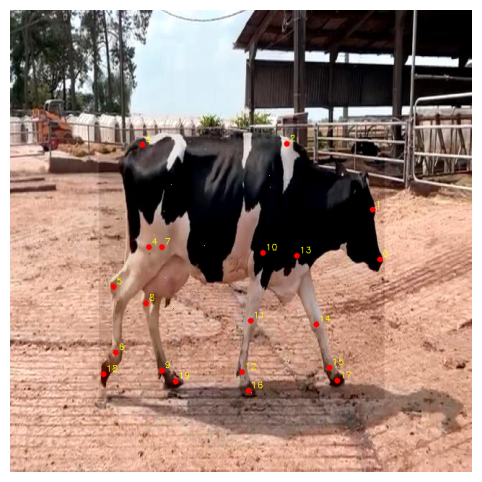

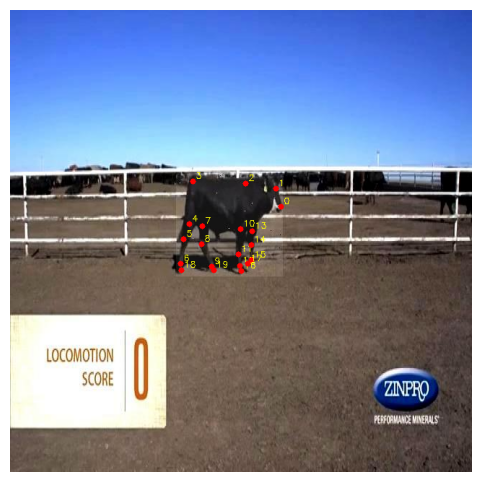

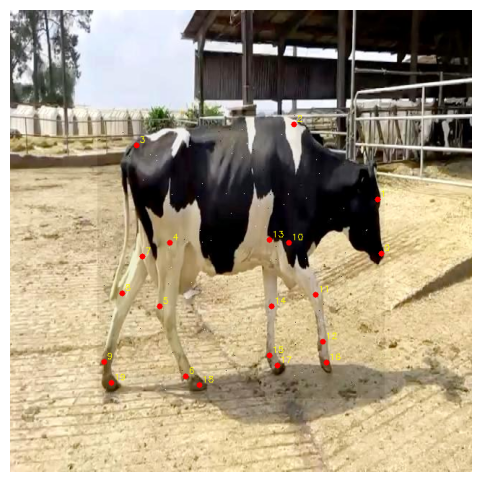

In [5]:
### Celula 4 — Verifică vizual adnotările

import random
import cv2
import matplotlib.pyplot as plt

train_images = list((dataset_root / "train" / "images").glob("*"))
random.seed(42)

for image_path in random.sample(train_images, min(3, len(train_images))):
    label_path = dataset_root / "train" / "labels" / f"{image_path.stem}.txt"
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)

    if label_path.exists():
        height, width = image.shape[:2]

        for line in label_path.read_text().splitlines():
            values = list(map(float, line.split()))
            keypoints = values[5:]

            for i in range(0, len(keypoints), 3):
                x, y, visibility = keypoints[i:i+3]

                if visibility > 0:
                    px, py = round(x * width), round(y * height)
                    cv2.circle(image, (px, py), 4, (255, 0, 0), -1)
                    cv2.putText(
                        image, str(i // 3), (px + 4, py - 4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 0), 1
                    )

    plt.figure(figsize=(10, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.show()


In [ ]:
### Celula 5 — Montează Google Drive

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
### Celula 6 — Verifică GPU-ul și pornește antrenarea

from pathlib import Path
import torch
from ultralytics import YOLO

DRIVE_DIR = Path("/content/drive/MyDrive")
assert DRIVE_DIR.exists(), "Drive-ul nu pare montat."

PROJECT_DIR = DRIVE_DIR / "cow_pose_runs"
RUN_NAME = "yolov8m_960"
RUN_DIR = PROJECT_DIR / RUN_NAME
WEIGHTS_DIR = RUN_DIR / "weights"

print("GPU disponibil:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "PyTorch nu vede GPU-ul. Selectează Runtime > Change runtime type > GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Rezultatele vor fi salvate în:", RUN_DIR)

model = YOLO("yolov8m-pose.pt")

results = model.train(
    data=str(COLAB_YAML),
    epochs=150,
    imgsz=960,
    batch=8,
    device=0,
    patience=30,
    workers=2,
    seed=42,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    save=True,
    save_period=5,
    plots=True,
    degrees=10.0,
    translate=0.08,
    scale=0.35,
    fliplr=0.5,
    mosaic=0.5,
    close_mosaic=10
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU disponibil: True
GPU: Tesla T4
Rezultatele vor fi salvate în: /content/drive/MyDrive/cow_pose_runs/yolov8m_960
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cow_pose.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, em

In [ ]:
### Celula 7 — Verifică checkpoint-urile din Drive

from pathlib import Path

WEIGHTS_DIR = Path(
    "/content/drive/MyDrive/cow_pose_runs/yolov8m_960/weights"
)

if WEIGHTS_DIR.exists():
    files = sorted(WEIGHTS_DIR.glob("*.pt"))

    if files:
        for file in files:
            print(f"{file.name}: {file.stat().st_size / 1024 / 1024:.1f} MB")
    else:
        print("Folderul există, dar nu are încă fișiere .pt.")
else:
    print("Folderul nu există încă. Verifică după ce se termină cel puțin o epocă.")

best.pt: 51.1 MB
epoch0.pt: 254.2 MB
epoch10.pt: 254.2 MB
epoch100.pt: 254.2 MB
epoch105.pt: 254.2 MB
epoch110.pt: 254.2 MB
epoch115.pt: 254.2 MB
epoch120.pt: 254.2 MB
epoch125.pt: 254.2 MB
epoch130.pt: 254.2 MB
epoch135.pt: 254.2 MB
epoch140.pt: 254.2 MB
epoch145.pt: 254.2 MB
epoch15.pt: 254.2 MB
epoch20.pt: 254.2 MB
epoch25.pt: 254.2 MB
epoch30.pt: 254.2 MB
epoch35.pt: 254.2 MB
epoch40.pt: 254.2 MB
epoch45.pt: 254.2 MB
epoch5.pt: 254.2 MB
epoch50.pt: 254.2 MB
epoch55.pt: 254.2 MB
epoch60.pt: 254.2 MB
epoch65.pt: 254.2 MB
epoch70.pt: 254.2 MB
epoch75.pt: 254.2 MB
epoch80.pt: 254.2 MB
epoch85.pt: 254.2 MB
epoch90.pt: 254.2 MB
epoch95.pt: 254.2 MB
last.pt: 51.1 MB


In [ ]:
  ### Celula 8 — Reia antrenarea după o întrerupere


  from pathlib import Path
  from ultralytics import YOLO

  last_checkpoint = Path(
      "/content/drive/MyDrive/cow_pose_runs/yolov8m_960/weights/last.pt"
  )

  if not last_checkpoint.exists():
      raise FileNotFoundError(f"Nu am găsit checkpoint-ul: {last_checkpoint}")

  model = YOLO(str(last_checkpoint))
  results = model.train(resume=True)

In [6]:
### Celula 9 — Evaluează modelul pe setul de test


from pathlib import Path
from ultralytics import YOLO

best_weights = Path(
    "/content/drive/MyDrive/cow_pose_runs/yolov8m_960/weights/best.pt"
)

if not best_weights.exists():
    raise FileNotFoundError(f"Nu am găsit modelul: {best_weights}")

best_model = YOLO(str(best_weights))

metrics = best_model.val(
    data=str(COLAB_YAML),
    split="test",
    imgsz=960,
    batch=8,
    device=0
)

print(metrics)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8m-pose summary (fused): 101 layers, 26,570,959 parameters, 0 gradients, 81.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1619.6±764.1 MB/s, size: 55.0 KB)
val: Scanning /content/cow_data/cow-pose-estimation.v1i.yolov8/test/labels... 104 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 104/104 924.7it/s 0.1s
val: New cache created: /content/cow_data/cow-pose-estimation.v1i.yolov8/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.5it/s 8.8s
                   all        1

In [9]:
### Celula 10 — Generează predicții pe imagini de test

test_images = list((dataset_root / "test" / "images").glob("*"))

predictions = best_model.predict(
    source=[str(p) for p in test_images[:8]],
    imgsz=960,
    conf=0.25,
    device=0,
    save=True
)

print("Predicțiile sunt salvate în:", predictions[0].save_dir)


0: 960x960 1 cow, 68.4ms
1: 960x960 1 cow, 68.4ms
2: 960x960 1 cow, 68.4ms
3: 960x960 1 cow, 68.4ms
4: 960x960 1 cow, 68.4ms
5: 960x960 1 cow, 68.4ms
6: 960x960 1 cow, 68.4ms
7: 960x960 1 cow, 68.4ms
Speed: 3.9ms preprocess, 68.4ms inference, 2.1ms postprocess per image at shape (1, 3, 960, 960)
Results saved to /content/runs/pose/predict
Predicțiile sunt salvate în: /content/runs/pose/predict


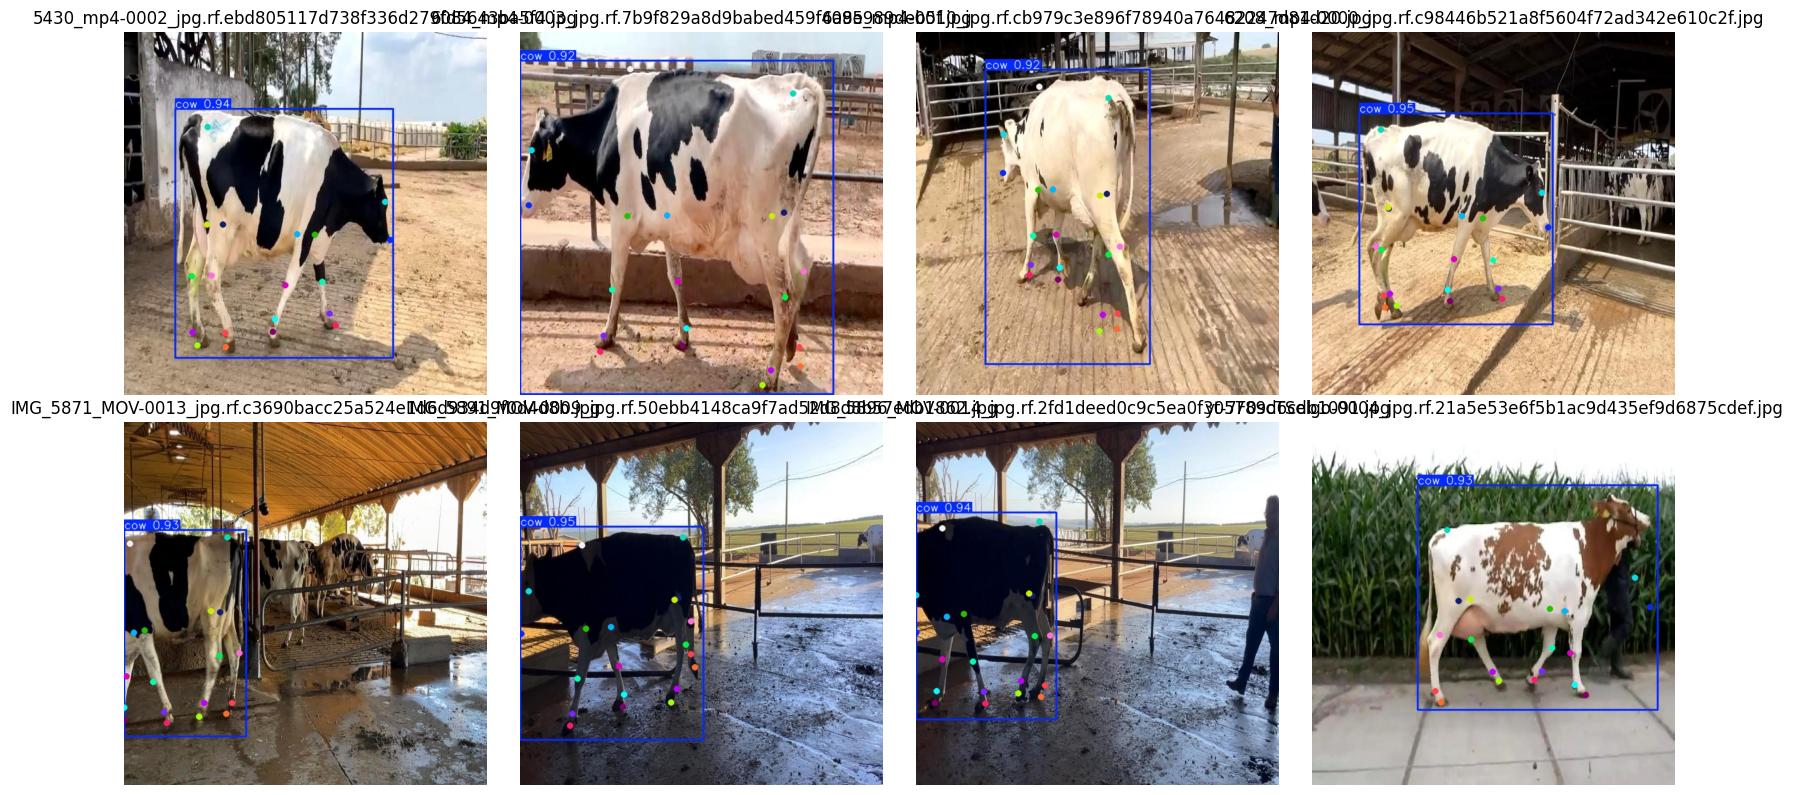

In [10]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import math

folder = Path("/content/runs/pose/predict")
imagini = sorted(
    p for p in folder.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

if not imagini:
    print(f"Nu am găsit imagini în {folder}")
else:
    coloane = 4
    randuri = math.ceil(len(imagini) / coloane)
    fig, axe = plt.subplots(randuri, coloane, figsize=(16, 4 * randuri))
    axe = [axe] if randuri * coloane == 1 else axe.flatten()

    for ax, cale in zip(axe, imagini):
        ax.imshow(Image.open(cale))
        ax.set_title(cale.name)
        ax.axis("off")

    for ax in axe[len(imagini):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
